# PCA Comparison (Last 400 ns): MUC2 Glycans vs No Glycans

- PC1 vs PC2 scatter plots
- Variance explained per PC
- Cumulative variance


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')

output_dir = "/home/computer2/analysis_simulations/analysis/pca_plots"
os.makedirs(output_dir, exist_ok=True)
print("Output dir:", output_dir)

Output dir: /home/computer2/analysis_simulations/analysis/pca_plots


## Load Data

In [2]:
# MUC2 No Glycans - Last 400 ns
nog_proj = pd.read_csv(
    "/home/computer2/analysis_simulations/analysis/muc2_noglyc_pca_dccm/muc2_noglyc_last400_projections.csv")
nog_var = pd.read_csv(
    "/home/computer2/analysis_simulations/analysis/muc2_noglyc_pca_dccm/muc2_noglyc_last400_variance.csv")

# MUC2 Glycans - Last 400 ns
gly_proj = pd.read_csv(
    "/home/computer2/analysis_simulations/analysis/muc2_normal_pca_dccm/muc2_norm_last400_pca_projections.csv")
gly_var = pd.read_csv(
    "/home/computer2/analysis_simulations/analysis/muc2_normal_pca_dccm/muc2_last400_norm_variance.csv")

print(f"No Glycans  - projections: {nog_proj.shape}, variance PCs: {len(nog_var)}")
print(f"Glycans     - projections: {gly_proj.shape}, variance PCs: {len(gly_var)}")

No Glycans  - projections: (8751, 3), variance PCs: 10
Glycans     - projections: (9987, 3), variance PCs: 10


## PC1 vs PC2 - Individual Scatter Plots

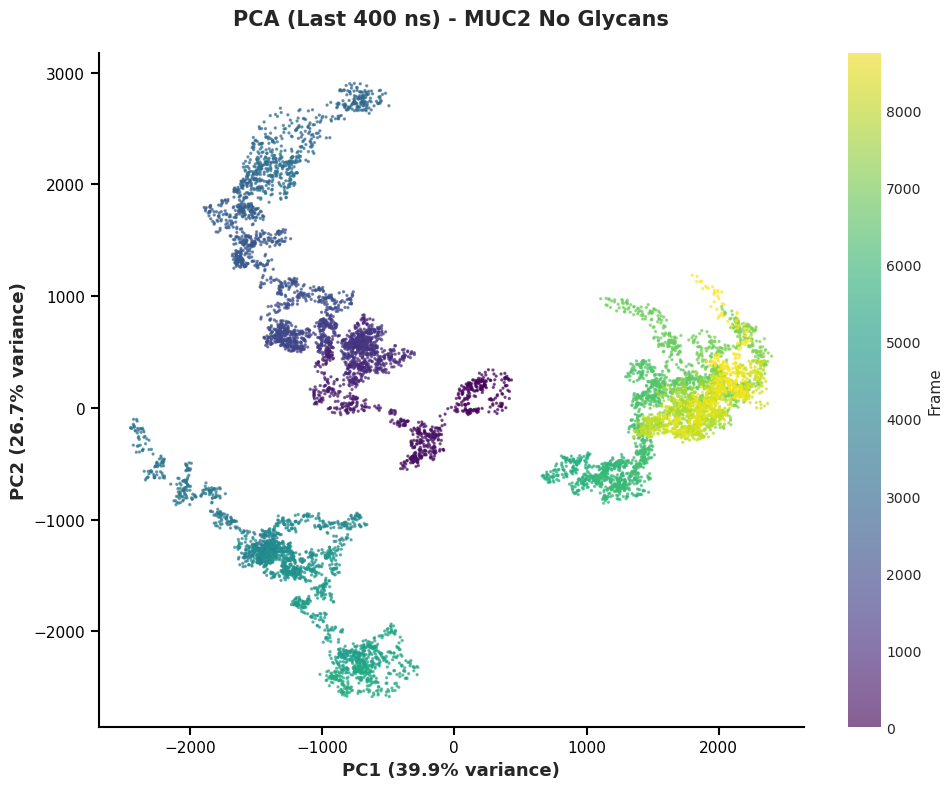

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/pca_last400_scatter_noglycans.png


In [3]:
# No Glycans - PC1 vs PC2 coloured by frame
pct1 = nog_var["variance"].iloc[0] / nog_var["variance"].sum() * 100
pct2 = nog_var["variance"].iloc[1] / nog_var["variance"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
sc = ax.scatter(nog_proj["PC1"], nog_proj["PC2"],
                c=np.arange(len(nog_proj)), cmap="viridis",
                s=2, alpha=0.6)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Frame", fontsize=11)

ax.set_xlabel(f"PC1 ({pct1:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_ylabel(f"PC2 ({pct2:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_title("PCA (Last 400 ns) - MUC2 No Glycans", fontsize=15, fontweight="bold", pad=20)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_last400_scatter_noglycans.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

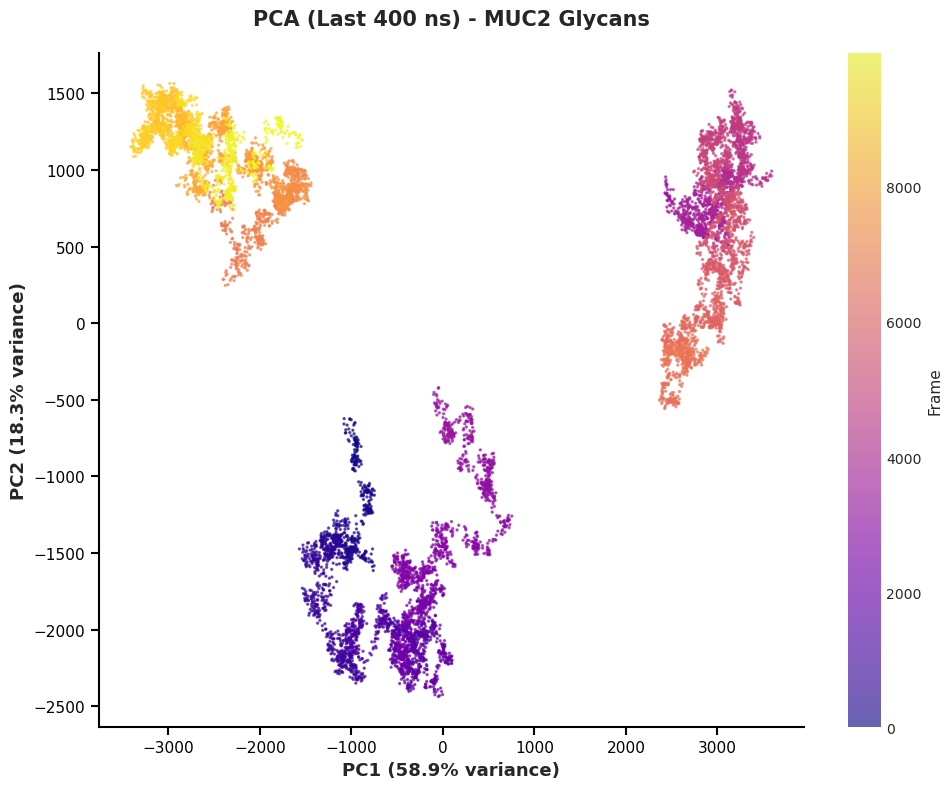

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/pca_last400_scatter_glycans.png


In [4]:
# Glycans - PC1 vs PC2 coloured by frame
pct1 = gly_var["variance"].iloc[0] / gly_var["variance"].sum() * 100
pct2 = gly_var["variance"].iloc[1] / gly_var["variance"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
sc = ax.scatter(gly_proj["PC1"], gly_proj["PC2"],
                c=np.arange(len(gly_proj)), cmap="plasma",
                s=2, alpha=0.6)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Frame", fontsize=11)

ax.set_xlabel(f"PC1 ({pct1:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_ylabel(f"PC2 ({pct2:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_title("PCA (Last 400 ns) - MUC2 Glycans", fontsize=15, fontweight="bold", pad=20)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_last400_scatter_glycans.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## PC1 vs PC2 - Both Systems Overlaid

In [ ]:
# Only enable after verifying that both projections use the same alignment,
# centering and PCA basis. Separately fitted PCA coordinates cannot be overlaid.
SHARED_PCA_BASIS_VERIFIED = False

if SHARED_PCA_BASIS_VERIFIED:
    fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
    
    ax.scatter(nog_proj["PC1"], nog_proj["PC2"],
               color="#A23B72", s=2, alpha=0.4, label="No Glycans")
    ax.scatter(gly_proj["PC1"], gly_proj["PC2"],
               color="#2E86AB", s=2, alpha=0.4, label="Glycans")
    
    ax.set_xlabel("PC1", fontsize=13, fontweight="bold")
    ax.set_ylabel("PC2", fontsize=13, fontweight="bold")
    ax.set_title("PCA (Last 400 ns): MUC2 Glycans vs No Glycans", fontsize=15, fontweight="bold", pad=20)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")
    ax.legend(fontsize=12, loc="best", markerscale=5)
    
    plt.tight_layout()
    out = os.path.join(output_dir, "pca_last400_scatter_comparison.png")
    plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out}")
else:
    print("Comparison skipped: verify a shared PCA basis before enabling this plot.")


## Variance Explained per PC

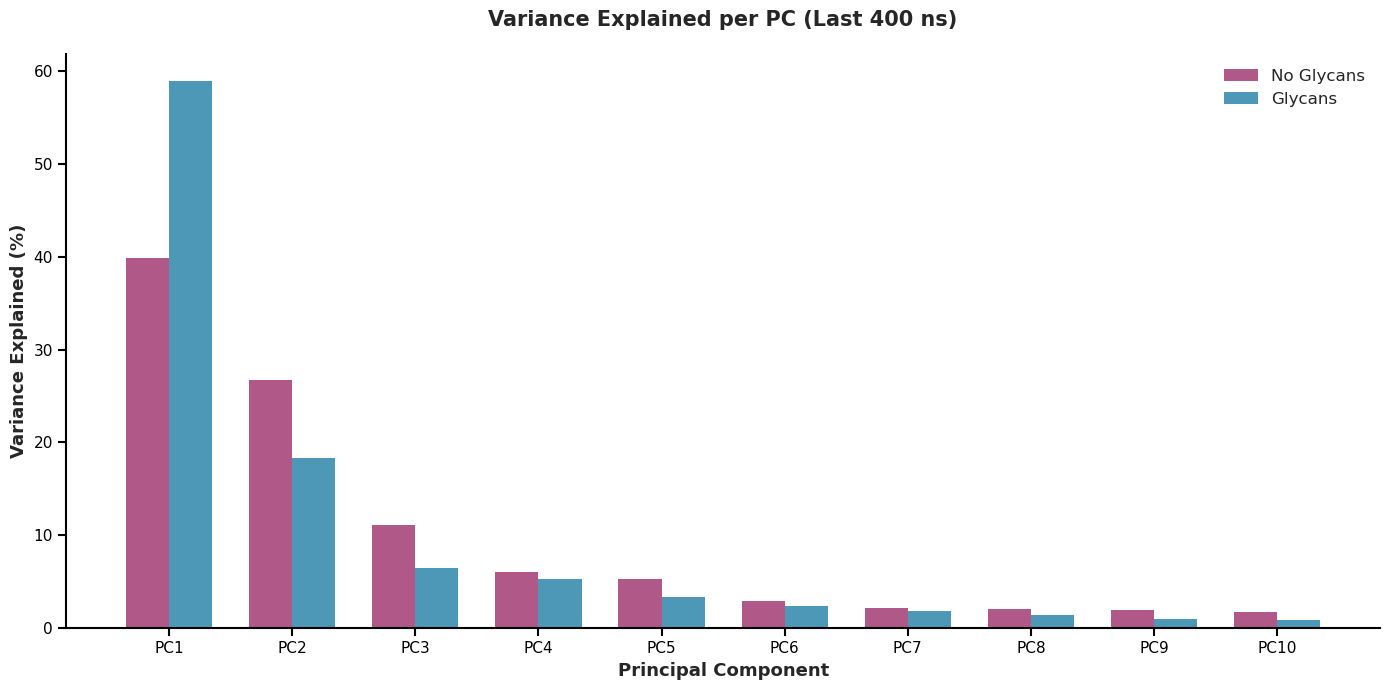

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/pca_last400_variance_explained.png


In [6]:
n_pcs = 10
nog_pct = (nog_var["variance"].iloc[:n_pcs] / nog_var["variance"].sum() * 100).values
gly_pct = (gly_var["variance"].iloc[:n_pcs] / gly_var["variance"].sum() * 100).values
pc_labels = [f"PC{i+1}" for i in range(n_pcs)]
x = np.arange(n_pcs)
width = 0.35

fig, ax = plt.subplots(figsize=(14, 7), dpi=100)
ax.bar(x - width/2, nog_pct, width, color="#A23B72", alpha=0.85, label="No Glycans")
ax.bar(x + width/2, gly_pct, width, color="#2E86AB", alpha=0.85, label="Glycans")

ax.set_xlabel("Principal Component", fontsize=13, fontweight="bold")
ax.set_ylabel("Variance Explained (%)", fontsize=13, fontweight="bold")
ax.set_title("Variance Explained per PC (Last 400 ns)", fontsize=15, fontweight="bold", pad=20)
ax.set_xticks(x)
ax.set_xticklabels(pc_labels)
ax.set_ylim(bottom=0)
ax.legend(fontsize=12)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_last400_variance_explained.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Cumulative Variance

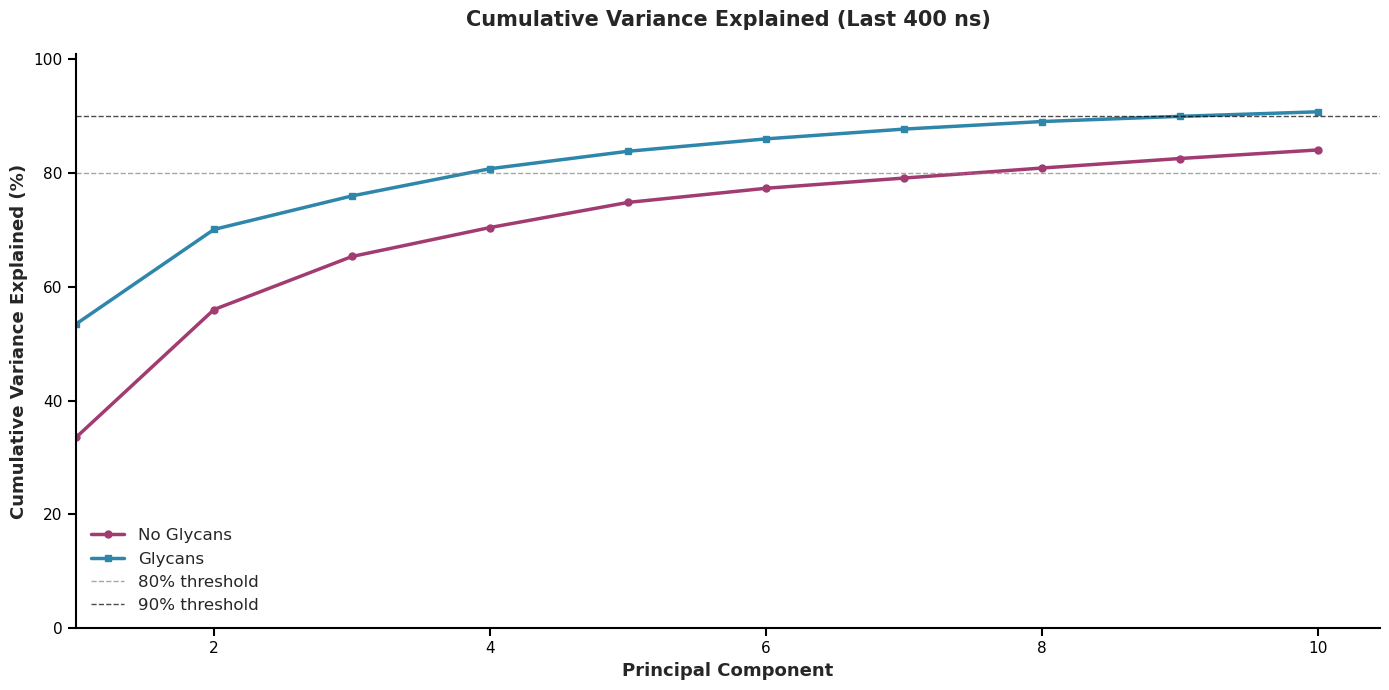

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/pca_last400_cumulative_variance.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 7), dpi=100)

ax.plot(nog_var["PC"], nog_var["cumulative_variance"] * 100,
        linewidth=2.5, color="#A23B72", marker="o", markersize=5, label="No Glycans")
ax.plot(gly_var["PC"], gly_var["cumulative_variance"] * 100,
        linewidth=2.5, color="#2E86AB", marker="s", markersize=5, label="Glycans")

ax.axhline(80, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="80% threshold")
ax.axhline(90, color="black", linestyle="--", linewidth=1, alpha=0.7, label="90% threshold")

ax.set_xlabel("Principal Component", fontsize=13, fontweight="bold")
ax.set_ylabel("Cumulative Variance Explained (%)", fontsize=13, fontweight="bold")
ax.set_title("Cumulative Variance Explained (Last 400 ns)", fontsize=15, fontweight="bold", pad=20)
ax.set_ylim(0, 101)
ax.set_xlim(left=1)
ax.legend(fontsize=12, loc="best")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_last400_cumulative_variance.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")